<a href="https://colab.research.google.com/github/trish272000/Thesis/blob/main/notebooks/02_baseline_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 02 — Baseline Forecasting (single-number forecasts)
**Thesis:** Uncertainty-Aware Carbon Digital Twin for Sustainable Industrial Systems

**Task.** Every evening the plant must decide how much green power to buy for **tomorrow**. So the twin forecasts
tomorrow's **hourly energy use** (24 values), and from it tomorrow's **emissions**
(energy × hourly grid factor) and **daily total**.

**Models in this notebook** (all give one number per hour, no range):

| Model | Idea |
|---|---|
| Naive: same as yesterday | Tomorrow's hour *h* = today's hour *h* |
| Naive: same as last week | Tomorrow's hour *h* = same weekday last week, hour *h* |
| XGBoost | Gradient-boosted trees on calendar and past-usage inputs |
| LSTM | Neural network that reads the past 7 days and outputs the next 24 hours |

The naive forecasts set the minimum standard: a model that cannot beat them is not useful.
These single-number forecasts are what the uncertainty-aware models (notebook 03) are compared with.

**Data periods** (from notebook 01): training Jan–Aug 2018 (August held back for early stopping),
checking Sep–Oct (kept untouched for notebook 03), testing Nov–Dec.

**Runtime:** a GPU helps the LSTM (Runtime → Change runtime type → T4 GPU) but is not required.

## Part 0 — Setup

In [1]:
import sys, os, json, time
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/thesis"
else:
    BASE = os.environ.get("THESIS_BASE", os.path.abspath("thesis"))

PROC, FIGS, MODELS = f"{BASE}/data/processed", f"{BASE}/results/figures", f"{BASE}/models"
RES = f"{BASE}/results"
for d in (FIGS, MODELS, RES):
    os.makedirs(d, exist_ok=True)
CONFIG = json.load(open(f"{BASE}/config.json"))
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/thesis


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch device:", DEVICE, "| XGBoost", xgb.__version__, "| PyTorch", torch.__version__)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Actual": "#23313B", "Naive (yesterday)": "#B0BEC5", "Naive (last week)": "#78909C",
          "XGBoost": "#0E7C7B", "LSTM": "#6C3FB0"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGS}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

PyTorch device: cuda | XGBoost 3.4.1 | PyTorch 2.11.0+cu130


## Part 1 — Hourly data
The 15-minute readings are added up to hours. Emissions use the CEA mean factor × hourly shape (from notebook 01).

In [3]:
steel = pd.read_parquet(f"{PROC}/steel_prepared.parquet")
daily_info = pd.read_parquet(f"{PROC}/steel_daily.parquet")[["day", "cap_t"]]

steel["ts_hour"] = steel["ts"].dt.floor("h")
hourly = (steel.groupby("ts_hour")
          .agg(kwh=("kwh", "sum"), co2_t=("co2_india_t", "sum"),
               ef=("grid_ef_t_per_mwh", "mean"), split=("split", "first"))
          .reset_index().rename(columns={"ts_hour": "ts"}))
hourly = hourly.set_index("ts").asfreq("h")                     # makes any missing hour visible
print("Missing hours:", int(hourly["kwh"].isna().sum()))
hourly["kwh"] = hourly["kwh"].interpolate(limit=3)
hourly["ef"] = hourly["ef"].ffill()
hourly["split"] = hourly["split"].ffill()
hourly = hourly.reset_index()
print(hourly.shape, hourly["ts"].min(), "to", hourly["ts"].max())
hourly.head()

Missing hours: 0
(8760, 5) 2018-01-01 00:00:00 to 2018-12-31 23:00:00


,ts,kwh,co2_t,ef,split
0,2018-01-01 00:00:00,13.72,0.010863,0.791782,train
1,2018-01-01 01:00:00,14.30,0.011348,0.793558,train
2,2018-01-01 02:00:00,13.76,0.010948,0.795624,train
3,2018-01-01 03:00:00,14.47,0.011538,0.797391,train
4,2018-01-01 04:00:00,13.89,0.011085,0.798091,train


### Public holidays
The plant is in South Korea, so its working pattern follows **Korean** public holidays (e.g. Lunar New Year, Chuseok).
Without this, the models would expect a normal working day on holidays.

In [4]:
KR_HOLIDAYS_2018 = pd.to_datetime([
    "2018-01-01",                                   # New Year
    "2018-02-15", "2018-02-16", "2018-02-17",       # Lunar New Year (Seollal)
    "2018-03-01",                                   # Independence Movement Day
    "2018-05-05", "2018-05-07",                     # Children's Day (+ substitute)
    "2018-05-22",                                   # Buddha's Birthday
    "2018-06-06",                                   # Memorial Day
    "2018-06-13",                                   # Local elections
    "2018-08-15",                                   # Liberation Day
    "2018-09-23", "2018-09-24", "2018-09-25", "2018-09-26",   # Chuseok (+ substitute)
    "2018-10-03", "2018-10-09",                     # National Foundation Day, Hangul Day
    "2018-12-25",                                   # Christmas
])

hourly["day"] = hourly["ts"].dt.normalize()
hourly["hour"] = hourly["ts"].dt.hour
hourly["dow"] = hourly["ts"].dt.dayofweek
hourly["month"] = hourly["ts"].dt.month
hourly["holiday"] = hourly["day"].isin(KR_HOLIDAYS_2018).astype(int)
hourly["off_day"] = ((hourly["dow"] >= 5) | (hourly["holiday"] == 1)).astype(int)

# Check: do holidays really look like weekends?
d = hourly.groupby("day").agg(kwh=("kwh", "sum"), dow=("dow", "first"), holiday=("holiday", "first"))
print("Mean daily kWh  | weekday:", round(d[(d.dow < 5) & (d.holiday == 0)].kwh.mean()),
      "| weekend:", round(d[d.dow >= 5].kwh.mean()),
      "| weekday holiday:", round(d[(d.dow < 5) & (d.holiday == 1)].kwh.mean()))

Mean daily kWh  | weekday: 3333 | weekend: 1126 | weekday holiday: 1510


## Part 2 — Inputs available the evening before
Only information known **before** the target day may be used. The dataset's load-type labels and reactive-power
readings are measured during the day itself, so they are **not** used as inputs.

| Input | Meaning |
|---|---|
| hour, day of week, month | calendar |
| off_day | weekend or public holiday |
| yesterday same hour | usage at the same hour one day earlier |
| last week same hour | usage at the same hour on the same weekday last week |
| yesterday total, last week same-day total | overall activity level |
| mean of last 7 days, same hour | typical level for this hour recently |
| last same-type day, same hour | usage at this hour on the most recent day of the same type (work day / off day) |

In [5]:
H = hourly.copy()
H["lag_24"] = H["kwh"].shift(24)
H["lag_168"] = H["kwh"].shift(168)
day_tot = H.groupby("day")["kwh"].sum()
H["yday_total"] = H["day"].map(day_tot.shift(1))
H["lweek_total"] = H["day"].map(day_tot.shift(7))
H["mean7_same_hour"] = H.groupby("hour")["kwh"].transform(lambda s: s.shift(1).rolling(7).mean())

# Most recent earlier day of the same type (work day or off day), same hour
days = H.groupby("day")["off_day"].first()
prev_same = {}
last_seen = {}
for dday, off in days.items():
    prev_same[dday] = last_seen.get(off)
    last_seen[off] = dday
kwh_by_dh = H.set_index(["day", "hour"])["kwh"]
H["prev_same_type_day"] = H["day"].map(prev_same)
H["lag_same_type"] = [kwh_by_dh.get((p, h), np.nan) if pd.notna(p) else np.nan
                      for p, h in zip(H["prev_same_type_day"], H["hour"])]

FEATURES = ["hour", "dow", "month", "off_day", "holiday", "lag_24", "lag_168", "yday_total",
            "lweek_total", "mean7_same_hour", "lag_same_type"]

# Early-stopping period: last 4 weeks of training (August); the rest is used for fitting
H["role"] = H["split"]
H.loc[(H["split"] == "train") & (H["month"] == 8), "role"] = "valid"
H = H.dropna(subset=FEATURES + ["kwh"]).reset_index(drop=True)
print(H["role"].value_counts().reindex(["train", "valid", "calib", "test"]))

role
train    4920
valid     744
calib    1464
test     1464
Name: count, dtype: int64


## Part 3 — Naive forecasts

In [6]:
preds = H[["ts", "day", "hour", "role", "kwh", "ef", "off_day"]].copy()
preds["Naive (yesterday)"] = H["lag_24"].values
preds["Naive (last week)"] = H["lag_168"].values

## Part 4 — XGBoost
One row per hour; the model predicts that hour's energy from the inputs above.
Training stops when the error on the held-back August weeks stops improving.

Best number of trees: 99


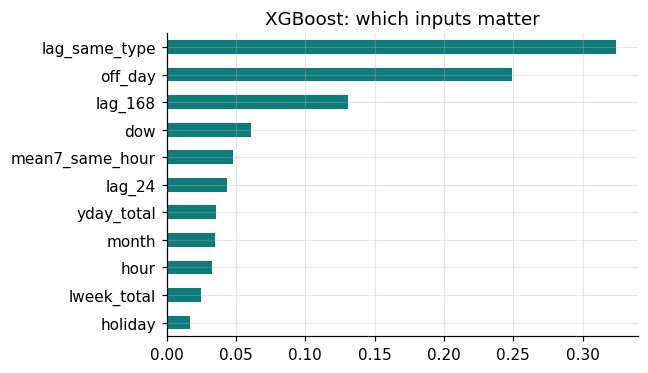

In [7]:
Xtr, ytr = H.loc[H.role == "train", FEATURES], H.loc[H.role == "train", "kwh"]
Xva, yva = H.loc[H.role == "valid", FEATURES], H.loc[H.role == "valid", "kwh"]

xgb_model = xgb.XGBRegressor(
    n_estimators=2000, learning_rate=0.03, max_depth=5, min_child_weight=3,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    objective="reg:squarederror", early_stopping_rounds=100, random_state=SEED)
xgb_model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
print("Best number of trees:", xgb_model.best_iteration + 1)

preds["XGBoost"] = np.clip(xgb_model.predict(H[FEATURES]), 0, None)
xgb_model.save_model(f"{MODELS}/xgb_baseline.json")

imp = pd.Series(xgb_model.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(6, 3.5), color="#0E7C7B", title="XGBoost: which inputs matter")
savefig("02_xgb_importance")

## Part 5 — LSTM
The LSTM reads the **past 7 days of hourly usage** (168 values) and then outputs **all 24 hours of tomorrow** at once.
It is also told tomorrow's calendar (hour, weekday, off-day), because that is known in advance.

* Training examples start at every hour of the training period (≈5,000 examples); forecasts that matter
  are those made at **midnight** for the next day, so evaluation uses only those.
* Usage is divided by the training-period maximum so values lie between 0 and 1.

In [8]:
LOOKBACK, HORIZON = 168, 24
series = hourly.set_index("ts")["kwh"]
SCALE = float(series[hourly.set_index("ts")["split"] == "train"].max())
y_all = (series / SCALE).values.astype(np.float32)
ts_all = series.index
cal = np.stack([np.sin(2*np.pi*ts_all.hour/24), np.cos(2*np.pi*ts_all.hour/24),
                np.sin(2*np.pi*ts_all.dayofweek/7), np.cos(2*np.pi*ts_all.dayofweek/7),
                (ts_all.dayofweek >= 5) | ts_all.normalize().isin(KR_HOLIDAYS_2018)], axis=1).astype(np.float32)
role_all = pd.Series(hourly["split"].values, index=ts_all)
role_all[(role_all == "train") & (ts_all.month == 8)] = "valid"

def make_windows(roles, midnight_only):
    X, C, Y, T = [], [], [], []
    for t in range(LOOKBACK, len(y_all) - HORIZON + 1):
        if midnight_only and ts_all[t].hour != 0:
            continue
        if role_all.iloc[t] not in roles or role_all.iloc[t + HORIZON - 1] not in roles:
            continue
        past = y_all[t - LOOKBACK:t]
        if np.isnan(past).any() or np.isnan(y_all[t:t + HORIZON]).any():
            continue
        X.append(np.stack([past, cal[t - LOOKBACK:t, 4]], axis=1))   # usage + off-day flag
        C.append(cal[t:t + HORIZON])                                   # tomorrow's calendar
        Y.append(y_all[t:t + HORIZON]); T.append(ts_all[t])
    return (torch.tensor(np.array(X)), torch.tensor(np.array(C)),
            torch.tensor(np.array(Y)), pd.DatetimeIndex(T))

Xtr_l, Ctr_l, Ytr_l, _ = make_windows({"train"}, midnight_only=False)
Xva_l, Cva_l, Yva_l, _ = make_windows({"valid"}, midnight_only=True)
print("LSTM training examples:", len(Xtr_l), "| early-stopping days:", len(Xva_l))

LSTM training examples: 4897 | early-stopping days: 31


  epoch   0  validation loss 0.02986
  epoch  10  validation loss 0.02265
  epoch  20  validation loss 0.01942
  epoch  30  validation loss 0.01832
  epoch  40  validation loss 0.02154
  epoch  50  validation loss 0.02135
Trained in 19s, 56 epochs, best validation loss 0.01783


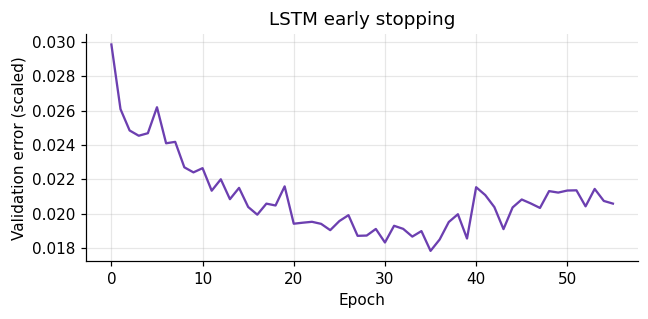

In [9]:
class DayAheadLSTM(nn.Module):
    def __init__(self, n_in=2, n_cal=5, hidden=64, dropout=0.2):
        super().__init__()
        self.encoder = nn.LSTM(n_in, hidden, num_layers=2, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(
            nn.Linear(hidden + n_cal, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x, c):
        _, (h, _) = self.encoder(x)                      # summary of the past week
        h = h[-1].unsqueeze(1).expand(-1, c.shape[1], -1)  # copy it for each of the 24 hours
        return self.head(torch.cat([h, c], dim=-1)).squeeze(-1)

def train_lstm(seed=SEED, epochs=200, patience=20, lr=1e-3, batch=128):
    torch.manual_seed(seed)
    model = DayAheadLSTM().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best, best_state, wait, history = np.inf, None, 0, []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_l))
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(Xtr_l[idx].to(DEVICE), Ctr_l[idx].to(DEVICE)), Ytr_l[idx].to(DEVICE))
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(Xva_l.to(DEVICE), Cva_l.to(DEVICE)), Yva_l.to(DEVICE)).item()
        history.append(v)
        if ep % 10 == 0:
            print(f"  epoch {ep:3d}  validation loss {v:.5f}")
        if v < best - 1e-6:
            best, best_state, wait = v, {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history

QUICK_TEST = os.environ.get("NB_QUICK_TEST") == "1"     # only for automated checks; leave unset
t0 = time.time()
lstm_model, hist = train_lstm(epochs=2 if QUICK_TEST else 200)
print(f"Trained in {time.time()-t0:.0f}s, {len(hist)} epochs, best validation loss {min(hist):.5f}")
torch.save({"state_dict": lstm_model.state_dict(), "scale": SCALE}, f"{MODELS}/lstm_baseline.pt")

plt.figure(figsize=(6, 3)); plt.plot(hist, color="#6C3FB0")
plt.xlabel("Epoch"); plt.ylabel("Validation error (scaled)"); plt.title("LSTM early stopping")
savefig("02_lstm_training")

In [10]:
# Day-ahead LSTM forecasts for every day that has a full past week
Xall, Call, _, Tall = make_windows({"train", "valid", "calib", "test"}, midnight_only=True)
lstm_model.eval()
with torch.no_grad():
    out = lstm_model(Xall.to(DEVICE), Call.to(DEVICE)).cpu().numpy() * SCALE
lstm_hourly = pd.Series(np.clip(out, 0, None).ravel(),
                        index=pd.DatetimeIndex([t + pd.Timedelta(hours=h) for t in Tall for h in range(HORIZON)]))
preds["LSTM"] = preds["ts"].map(lstm_hourly)
print("Days with LSTM forecasts:", len(Tall))

Days with LSTM forecasts: 358


## Part 6 — How good are the forecasts?
Errors are reported for the **checking** and **testing** periods (never seen in training).

* **Hourly error (kWh):** average size of the miss for one hour (MAE) and its square-root-of-squares version (RMSE).
* **Daily emissions error:** this is what matters for buying green power. MAPE is the average miss as a
  percentage of the day's actual emissions.

In [11]:
MODELS_LIST = ["Naive (yesterday)", "Naive (last week)", "XGBoost", "LSTM"]
P = preds.dropna(subset=MODELS_LIST).copy()
for m in MODELS_LIST + ["kwh"]:
    P[f"co2_{m}"] = P[m] / 1000 * P["ef"]                    # tonnes CO2 for that hour

def metrics(df):
    rows = {}
    day = df.groupby("day")
    act = day["co2_kwh"].sum()
    for m in MODELS_LIST:
        err_h = df[m] - df["kwh"]
        fc = day[f"co2_{m}"].sum()
        rows[m] = {
            "hourly MAE (kWh)": err_h.abs().mean(),
            "hourly RMSE (kWh)": np.sqrt((err_h ** 2).mean()),
            "daily CO2 MAE (t)": (fc - act).abs().mean(),
            "daily CO2 MAPE (%)": 100 * ((fc - act).abs() / act.clip(lower=0.05)).mean(),
            "daily CO2 bias (t)": (fc - act).mean(),
        }
    return pd.DataFrame(rows).T

results = {r: metrics(P[P.role == r]) for r in ["calib", "test"]}
table = pd.concat(results, names=["period", "model"])
table.to_csv(f"{RES}/02_baseline_metrics.csv")
print(table.round(3).to_string())

                          hourly MAE (kWh)  hourly RMSE (kWh)  daily CO2 MAE (t)  daily CO2 MAPE (%)  daily CO2 bias (t)
period model                                                                                                            
calib  Naive (yesterday)            58.136            108.376              0.789              96.430              -0.015
       Naive (last week)            46.381             88.315              0.588              78.030              -0.067
       XGBoost                      42.680             72.783              0.458             105.481               0.127
       LSTM                         47.341             70.482              0.451              87.093               0.181
test   Naive (yesterday)            54.114            100.695              0.637              94.229               0.039
       Naive (last week)            48.189             91.501              0.548              81.254               0.119
       XGBoost                  

*Bias* shows whether a model tends to over-forecast (positive) or under-forecast (negative) daily emissions.
Under-forecasting is the dangerous direction: the plant buys too little green power and crosses the limit.

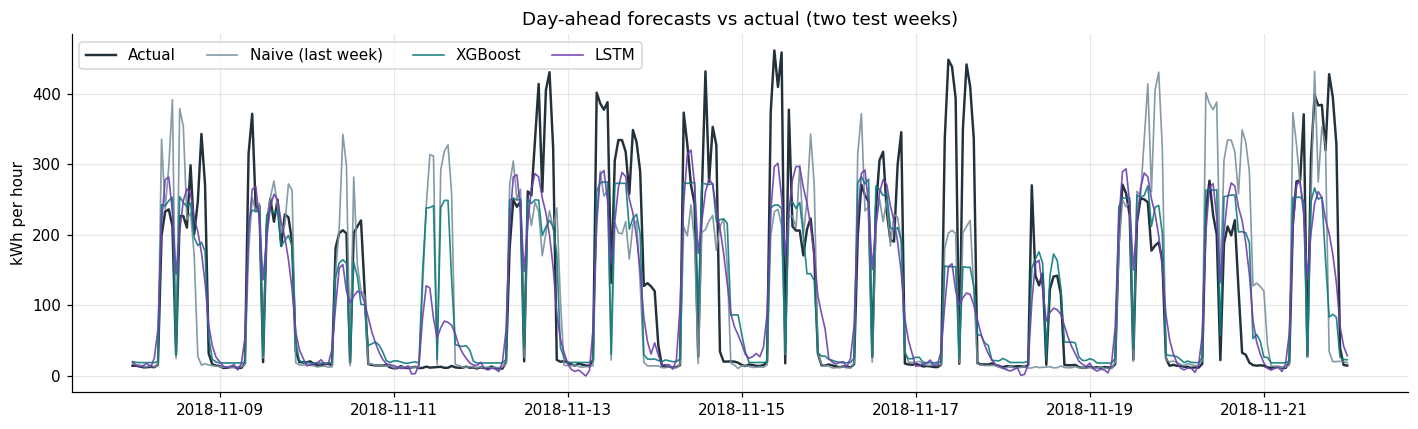

In [12]:
# Two test weeks: forecast vs actual
week = P[(P.role == "test")].copy()
start = week["day"].min() + pd.Timedelta(days=7)
w = week[(week["ts"] >= start) & (week["ts"] < start + pd.Timedelta(days=14))]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(w["ts"], w["kwh"], color=COLORS["Actual"], lw=1.6, label="Actual")
for m in ["Naive (last week)", "XGBoost", "LSTM"]:
    ax.plot(w["ts"], w[m], color=COLORS[m], lw=1.1, label=m, alpha=0.9)
ax.set(ylabel="kWh per hour", title="Day-ahead forecasts vs actual (two test weeks)")
ax.legend(ncol=4)
savefig("02_forecast_vs_actual")

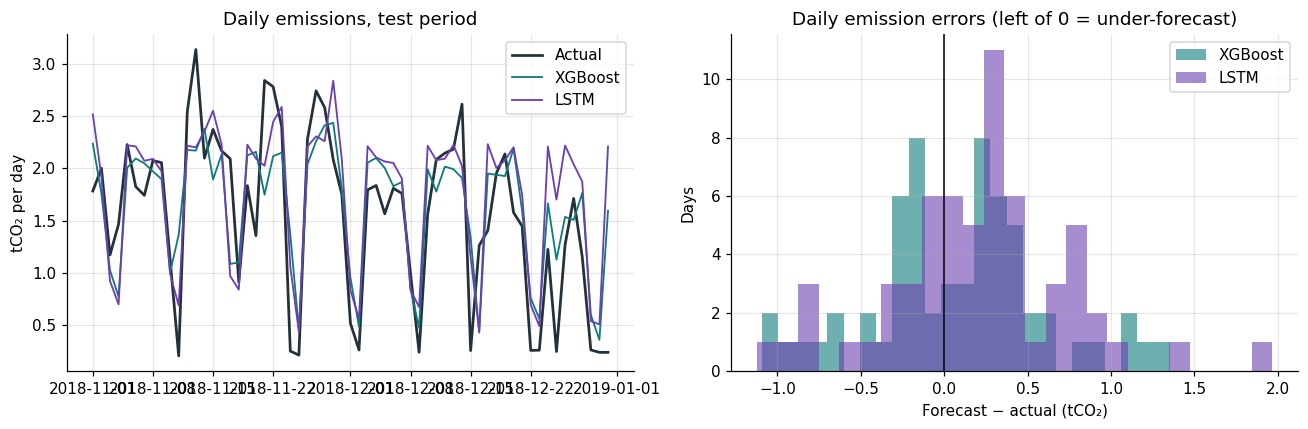

In [13]:
# Daily emissions: forecast vs actual, test period
D = P[P.role.isin(["calib", "test"])].groupby(["day", "role"])[
    ["co2_kwh"] + [f"co2_{m}" for m in MODELS_LIST]].sum().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
t = D[D.role == "test"]
ax[0].plot(t["day"], t["co2_kwh"], color=COLORS["Actual"], lw=1.8, label="Actual")
for m in ["XGBoost", "LSTM"]:
    ax[0].plot(t["day"], t[f"co2_{m}"], color=COLORS[m], lw=1.2, label=m)
ax[0].set(ylabel="tCO₂ per day", title="Daily emissions, test period"); ax[0].legend()
for m in ["XGBoost", "LSTM"]:
    ax[1].hist(t[f"co2_{m}"] - t["co2_kwh"], bins=25, alpha=0.6, color=COLORS[m], label=m)
ax[1].axvline(0, color="black", lw=1)
ax[1].set(xlabel="Forecast − actual (tCO₂)", ylabel="Days", title="Daily emission errors (left of 0 = under-forecast)")
ax[1].legend()
savefig("02_daily_errors")

## Part 7 — Preview: buying green power with a single-number forecast
The evening before each day, the plant buys the green share that **would** keep emissions exactly at the limit
**if the forecast were right**:  *f* = max(0, 1 − limit / forecast emissions).

Then the real day happens. Whenever actual emissions turn out higher than forecast, the plant crosses the limit.
This is the failure that the uncertainty-aware twin (notebooks 03–04) is designed to fix.

In [14]:
D = D.merge(daily_info, on="day", how="left")
premium = CONFIG["green_premium_rs_per_kwh"]
energy = P.groupby("day")["kwh"].sum()
rows = []
for m in ["Naive (last week)", "XGBoost", "LSTM", "Perfect knowledge"]:
    fc = D["co2_kwh"] if m == "Perfect knowledge" else D[f"co2_{m}"]
    f = np.clip(1 - D["cap_t"] / fc.clip(lower=1e-6), 0, 1)
    realised = (1 - f) * D["co2_kwh"]
    over = realised > D["cap_t"] * (1 + 1e-4)          # tiny tolerance for rounding
    cost = f * D["day"].map(energy) * premium
    for r in ["calib", "test"]:
        k = D["role"] == r
        rows.append({"period": r, "method": m,
                     "days over limit (%)": 100 * over[k].mean(),
                     "excess CO2 on those days (t)": (realised - D["cap_t"])[k & over].sum(),
                     "green power cost (Rs)": cost[k].sum()})
preview = pd.DataFrame(rows).set_index(["period", "method"])
preview.to_csv(f"{RES}/02_green_power_preview.csv")
print(preview.round(1).to_string())

                          days over limit (%)  excess CO2 on those days (t)  green power cost (Rs)
period method                                                                                     
calib  Naive (last week)                 29.5                           6.6                 3392.6
test   Naive (last week)                 29.5                           6.9                 3443.5
calib  XGBoost                           32.8                           6.9                 2015.7
test   XGBoost                           34.4                           6.9                 2031.6
calib  LSTM                              31.1                           6.7                 2602.4
test   LSTM                              29.5                           6.2                 2944.0
calib  Perfect knowledge                  0.0                           0.0                 4928.2
test   Perfect knowledge                  0.0                           0.0                 5029.6


**How to read this.** With perfect knowledge, no day crosses the limit. With single-number forecasts, some days still
do, because on those days the forecast was too low and too little green power was bought. Notebook 03 adds calibrated
95% ranges, and notebook 04 uses them to buy *enough* green power without over-buying every day.

## Part 8 — Save forecasts for the next notebooks

In [15]:
P.to_parquet(f"{PROC}/baseline_forecasts_hourly.parquet", index=False)
D.to_parquet(f"{PROC}/baseline_forecasts_daily.parquet", index=False)
json.dump({"features": FEATURES, "lookback": LOOKBACK, "horizon": HORIZON, "scale": SCALE,
           "xgb_best_trees": int(xgb_model.best_iteration + 1), "lstm_epochs": len(hist)},
          open(f"{MODELS}/baseline_info.json", "w"), indent=2)
print("Saved forecasts, models and metrics.")

Saved forecasts, models and metrics.


### Save to GitHub
File → **Save a copy in GitHub** → `notebooks/02_baseline_forecasting.ipynb`.

### Next
**Notebook 03 — Uncertainty-aware forecasts:** model ensembles, dropout sampling and low–high (quantile) models,
then conformal calibration on the checking period to make the 95% ranges trustworthy.